# EDA na Prática — Anime Recommendations Database

Neste notebook será realizada uma Análise Exploratória de Dados (EDA) utilizando o dataset Anime Recommendations Database, disponível no Kaggle.

O objetivo é compreender a estrutura dos dados, identificar valores ausentes e outliers, analisar distribuições, estudar relações entre variáveis e verificar possíveis padrões envolvendo características como `rating`, `members`, `type`, `genre` e `episodes`.

A EDA será realizada de forma iterativa: primeiro observamos os dados originais, depois tomamos decisões de tratamento e, por fim, comparamos os resultados antes e depois das alterações.

## Setup de Bibliotecas e Dados

In [124]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)

COR_NEUTRA = "lightgray"
COR_CONTEXTO = "#e9d4d0"
COR_DESTAQUE = "#2d223a"
COR_ALERTA = "tab:red"

## Carregando o Dataset

In [125]:
import kagglehub
import os

path = kagglehub.dataset_download(
    "CooperUnion/anime-recommendations-database"
)

df = pd.read_csv(
    os.path.join(path, "anime.csv")
)

# Converter episódios para valor numérico.
# Valores como "Unknown" serão convertidos para NaN.
df["episodes"] = pd.to_numeric(
    df["episodes"],
    errors="coerce"
)

df.head()

,anime_id,name,genre,type,episodes,rating,members
0,32281,Kimi no Na wa.,"Drama, Romance, School, Supernatural",Movie,1.0,9.37,200630
1,5114,Fullmetal Alchemist: Brotherhood,"Action, Adventure, Drama, Fantasy, Magic, Mili...",TV,64.0,9.26,793665
2,28977,Gintama°,"Action, Comedy, Historical, Parody, Samurai, S...",TV,51.0,9.25,114262
3,9253,Steins;Gate,"Sci-Fi, Thriller",TV,24.0,9.17,673572
4,9969,Gintama&#039;,"Action, Comedy, Historical, Parody, Samurai, S...",TV,51.0,9.16,151266


## 1. Princípio Estrutural

Antes de qualquer análise, precisamos entender a estrutura dos dados: quantas linhas e colunas existem, quais tipos de dados estão presentes, se existem valores ausentes e se há registros duplicados.

O dataset utilizado contém informações sobre animes, incluindo identificador, nome, gênero, tipo, quantidade de episódios, avaliação média e número de membros da comunidade.

### Dimensão e Tipos de Dados

In [126]:
df.shape

(12294, 7)

In [127]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12294 entries, 0 to 12293
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   anime_id  12294 non-null  int64  
 1   name      12294 non-null  object 
 2   genre     12232 non-null  object 
 3   type      12269 non-null  object 
 4   episodes  11954 non-null  float64
 5   rating    12064 non-null  float64
 6   members   12294 non-null  int64  
dtypes: float64(2), int64(2), object(3)
memory usage: 672.5+ KB


In [128]:
df.describe()

,anime_id,episodes,rating,members
count,12294.000000,11954.000000,12064.000000,1.229400e+04
mean,14058.221653,12.382550,6.473902,1.807134e+04
std,11455.294701,46.865352,1.026746,5.482068e+04
min,1.000000,1.000000,1.670000,5.000000e+00
25%,3484.250000,1.000000,5.880000,2.250000e+02
50%,10260.500000,2.000000,6.570000,1.550000e+03
75%,24794.500000,12.000000,7.180000,9.437000e+03
max,34527.000000,1818.000000,10.000000,1.013917e+06


### Duplicadas

In [129]:
df.duplicated().sum()

np.int64(0)

### Definição do atributo alvo

**Atributo alvo**

O dataset de animes utilizado nesta análise não possui um atributo alvo específico. Como o objetivo deste trabalho é realizar uma análise exploratória dos dados, não será criada uma variável alvo artificial. As análises serão realizadas utilizando as próprias características do dataset, como rating, members, type, genre e episodes.

## 2. Dados Faltantes

In [130]:
df.isna().sum()

anime_id      0
name          0
genre        62
type         25
episodes    340
rating      230
members       0
dtype: int64

**Discussao:** Alguma feature tem dados ausentes nos seus dados?

**Resposta**: Sim. Após a conversão da variável `episodes` para formato numérico, observamos valores ausentes em variáveis como `genre`, `type`, `episodes` e `rating`. Esses casos serão analisados antes da decisão de tratamento.

#### Identificando o mecanismo de dados ausentes

**Conhecimento de Domínio**

O dataset pertence ao domínio de animes e contém informações como:

- `genre`: gêneros associados ao anime;
- `type`: formato do anime, como TV, Movie, OVA e ONA;
- `episodes`: quantidade de episódios;
- `rating`: avaliação média do anime;
- `members`: quantidade de membros que adicionaram o anime às suas listas.

Alguns registros não possuem todas essas informações disponíveis. Por exemplo, determinados animes podem não possuir quantidade de episódios definida, gênero registrado, tipo informado ou quantidade suficiente de avaliações para gerar um rating.

Apenas observando o dataset não é possível determinar com certeza o mecanismo que causou essas ausências.

**As ausências ocorrem juntas?**

Além de contar quantos valores estão ausentes em cada variável, é interessante verificar se as ausências aparecem simultaneamente nos mesmos registros.

Como existem várias colunas com valores ausentes, vamos analisar a coocorrência entre todas elas.

In [131]:
cols_com_ausentes = df.columns[df.isna().any()].tolist()
print("Colunas com ausentes:", cols_com_ausentes)
print(df[cols_com_ausentes].isna().sum())


Colunas com ausentes: ['genre', 'type', 'episodes', 'rating']
genre        62
type         25
episodes    340
rating      230
dtype: int64


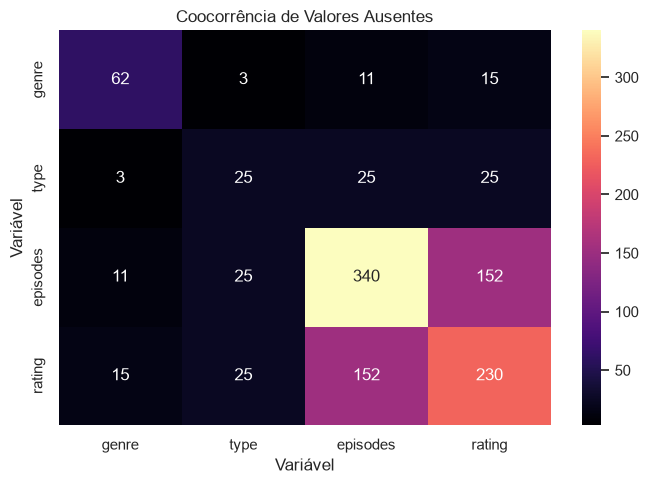

In [132]:
cols_com_ausentes = df.columns[df.isna().any()].tolist()

ausencias = df[cols_com_ausentes].isna().astype(int)

coocorrencia = ausencias.T @ ausencias

plt.figure(figsize=(7, 5))

sns.heatmap(
    coocorrencia,
    annot=True,
    fmt="d",
    cmap="magma"
)

plt.title("Coocorrência de Valores Ausentes")
plt.xlabel("Variável")
plt.ylabel("Variável")

plt.tight_layout()
plt.show()

**Interpretação dos dados ausentes**

Os mecanismos de ausência podem ser classificados como:

- **MCAR (Missing Completely At Random):** a ausência ocorre de forma completamente aleatória;
- **MAR (Missing At Random):** a ausência pode estar relacionada a outras características observadas no dataset;
- **MNAR (Missing Not At Random):** a ausência está relacionada ao próprio valor que está faltando.

No dataset de animes, não é possível determinar com certeza o mecanismo de ausência apenas observando os dados.

Por exemplo, valores ausentes em `episodes` podem ocorrer porque a quantidade de episódios ainda não estava definida ou disponível no momento da coleta. Da mesma forma, informações de `genre`, `type` ou `rating` podem não estar disponíveis para determinados títulos.

A análise de coocorrência permite observar se as ausências aparecem simultaneamente nas mesmas linhas, mas não é suficiente, sozinha, para determinar se o mecanismo é MCAR, MAR ou MNAR.

Por isso, a decisão de tratamento será baseada principalmente na quantidade de registros afetados e no impacto da remoção dessas linhas sobre o conjunto de dados.

## 3. Princípio Distribucional

Ainda com os dados originais (sem tratar ausentes ou outliers), vamos calcular as estatísticas descritivas e olhar as distribuições. Esse retrato "antes" é o que vai *orientar as decisões de tratamento* na próxima seção. Por exemplo, se uma variável for muito assimétrica, faz mais sentido imputar com a mediana do que com a média.

In [133]:
# Variáveis quantitativas e qualitativas do dataset de anime
VARS_QUANT = ["episodes", "rating", "members"]
VARS_QUALI = ["genre", "type"]

### Tabela descritiva, com assimetria e curtose

desc = df[VARS_QUANT].describe().T
desc["skewness"] = df[VARS_QUANT].skew()
desc["kurtosis"] = df[VARS_QUANT].kurtosis()

(
    desc[["mean", "50%", "std", "min", "max", "skewness", "kurtosis"]]
    .rename(columns={"50%": "median"})
    .round(2)
    .style.format(precision=2)
    .background_gradient(cmap="magma", subset=["skewness", "kurtosis"])
)

,mean,median,std,min,max,skewness,kurtosis
episodes,12.38,2.00,46.87,1.00,1818.00,23.39,733.28
rating,6.47,6.57,1.03,1.67,10.00,-0.54,0.51
members,18071.34,1550.00,54820.68,5.00,1013917.00,6.68,62.86


**Interpretação:** As variáveis `episodes` e `members` apresentam forte assimetria positiva e elevada curtose, indicando que a maioria dos animes possui valores relativamente baixos enquanto poucos títulos apresentam números muito elevados.

A variável `rating`, por outro lado, possui uma distribuição muito mais concentrada e apresenta assimetria bem menor.

### Distribuições de dados

Nesta etapa, analisamos a distribuição das variáveis quantitativas do dataset de animes. Os histogramas permitem observar a frequência dos valores, a concentração dos dados, possíveis assimetrias e valores extremos antes de realizar o tratamento dos dados.


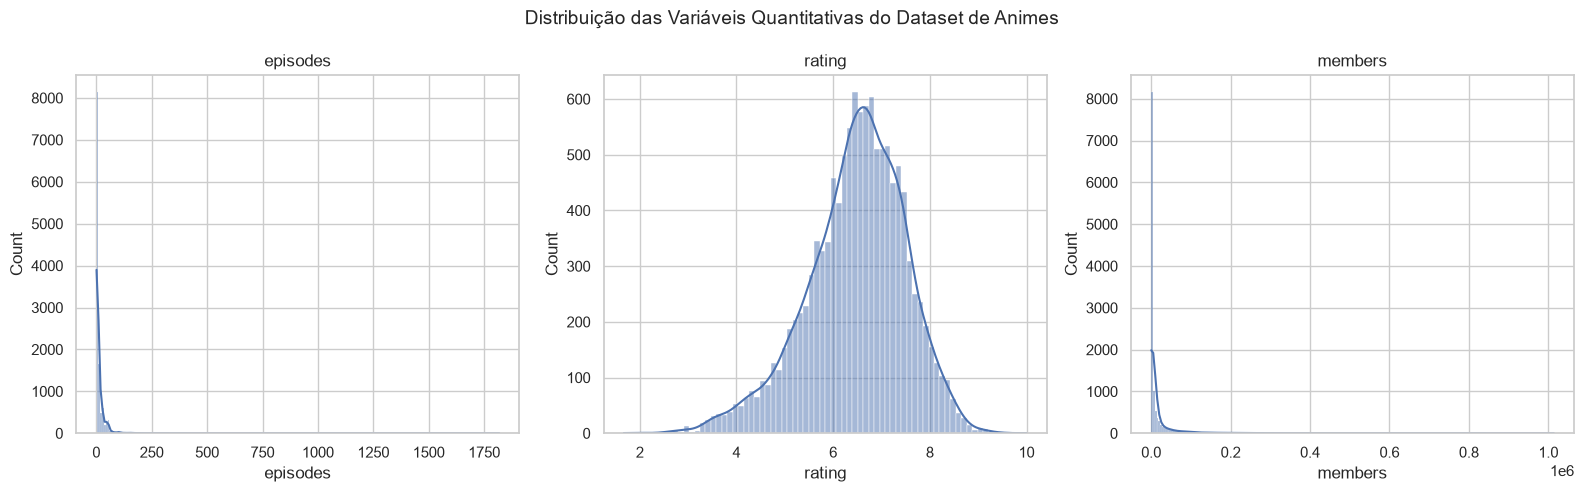

In [134]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for i, col in enumerate(VARS_QUANT):
    sns.histplot(
        data=df,
        x=col,
        kde=True,
        ax=axes[i]
    )
    axes[i].set_title(col)

fig.suptitle(
    "Distribuição das Variáveis Quantitativas do Dataset de Animes",
    fontsize=14
)

plt.tight_layout()
plt.show()

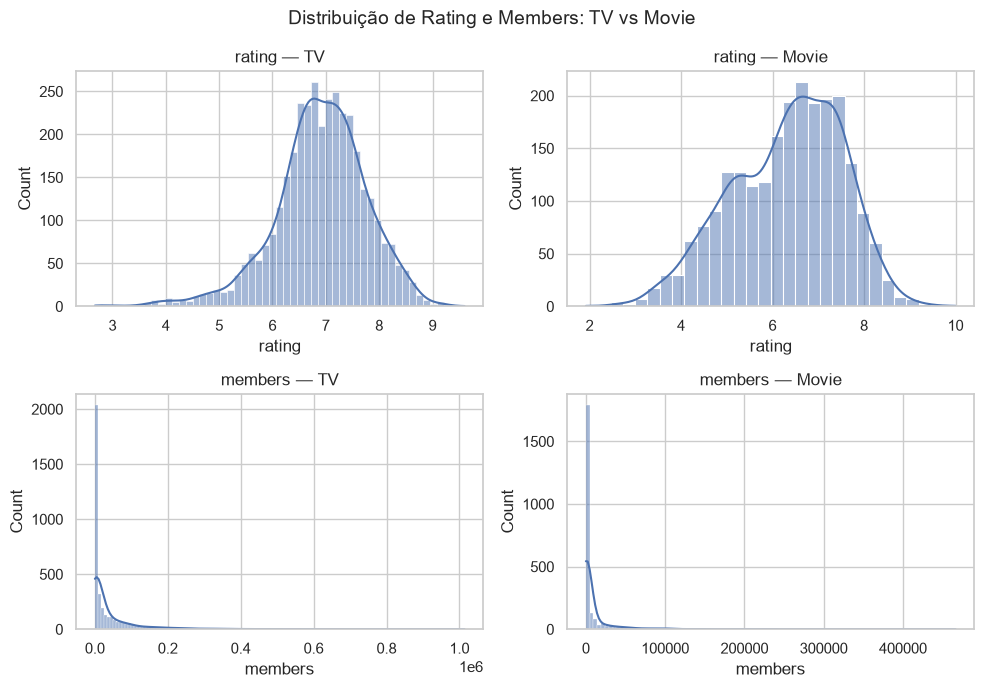

In [135]:
VARS_COMPARACAO = ["rating", "members"]

fig, axes = plt.subplots(
    len(VARS_COMPARACAO),
    2,
    figsize=(10, 7)
)

for i, col in enumerate(VARS_COMPARACAO):

    for j, tipo in enumerate(["TV", "Movie"]):
        subset = df[df["type"] == tipo]

        sns.histplot(
            data=subset,
            x=col,
            kde=True,
            ax=axes[i, j]
        )

        axes[i, j].set_title(f"{col} — {tipo}")

fig.suptitle(
    "Distribuição de Rating e Members: TV vs Movie",
    fontsize=14
)

plt.tight_layout()
plt.show()

**Interpretação:** As distribuições de `rating` de TV e Movie apresentam formatos semelhantes, embora os animes do tipo TV estejam mais concentrados em ratings um pouco mais elevados.

A variável `members` apresenta forte assimetria nos dois grupos, com poucos títulos concentrando valores muito elevados de popularidade.

#### Testes de Aderência

**O rating segue uma distribuição normal?**

Vamos utilizar o teste de Shapiro-Wilk para avaliar a hipótese de normalidade da variável `rating`, juntamente com o QQ-Plot como apoio visual.

Como o dataset possui mais de 5.000 observações, utilizaremos uma amostra de até 5.000 registros no teste de Shapiro-Wilk.

Shapiro-Wilk - rating: estatística=0.9832, p-valor=6.236e-24
Rejeita H0 (normalidade)? Sim (alpha = 0.05)


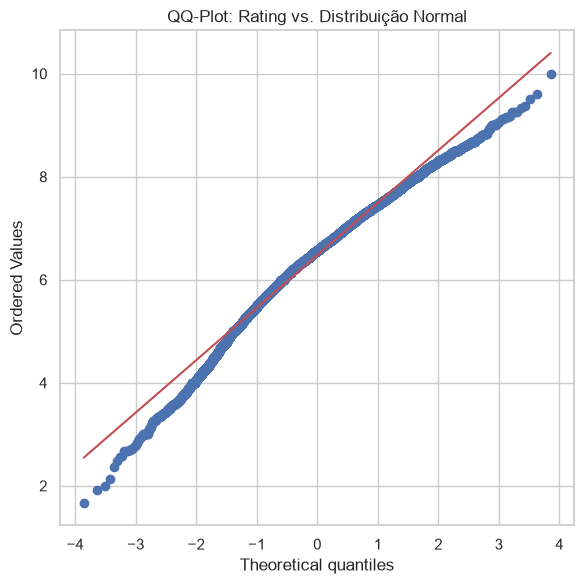

In [136]:
dados_rating = df["rating"].dropna()

amostra_rating = dados_rating.sample(
    n=min(5000, len(dados_rating)),
    random_state=42
)

stat_sw, p_valor_sw = stats.shapiro(amostra_rating)

print(
    f"Shapiro-Wilk - rating: "
    f"estatística={stat_sw:.4f}, "
    f"p-valor={p_valor_sw:.4g}"
)

print(
    "Rejeita H0 (normalidade)?",
    "Sim" if p_valor_sw < 0.05 else "Não",
    "(alpha = 0.05)"
)

# QQ-Plot

fig, ax = plt.subplots(figsize=(6, 6))

stats.probplot(
    dados_rating,
    dist="norm",
    plot=ax
)

ax.set_title("QQ-Plot: Rating vs. Distribuição Normal")

plt.tight_layout()
plt.show()

**Como interpretar:**

No QQ-Plot, quanto mais próximos os pontos estiverem da linha de referência, mais próxima a distribuição está de uma distribuição normal. Desvios maiores, principalmente nas extremidades, indicam diferenças em relação à normalidade.

**Interpretação:** O teste de Shapiro-Wilk apresentou p-valor inferior a 0,05, indicando rejeição da hipótese de normalidade para a variável `rating`.

O QQ-Plot reforça esse resultado, pois os pontos apresentam desvios em relação à linha teórica, principalmente nas extremidades da distribuição.

Como o dataset possui muitas observações, o teste de Shapiro-Wilk foi realizado utilizando uma amostra de até 5.000 registros, evitando problemas associados ao uso do teste em amostras muito grandes.

In [137]:
resultados_shapiro = []

for col in VARS_QUANT:

    dados = df[col].dropna()

    amostra = dados.sample(
        n=min(5000, len(dados)),
        random_state=42
    )

    stat, p = stats.shapiro(amostra)

    resultados_shapiro.append({
        "variavel": col,
        "estatistica": round(stat, 4),
        "p_valor": f"{p:.4g}",
        "rejeita_normalidade": p < 0.05
    })

pd.DataFrame(
    resultados_shapiro
).set_index("variavel")

,estatistica,p_valor,rejeita_normalidade
variavel,,,
episodes,0.2566,5.832e-89,True
rating,0.9832,6.236e-24,True
members,0.3614,1.58e-85,True


**ECDF — outra forma de ver a distribuição**

Diferente do histograma, a ECDF não depende da escolha do número de bins. Para cada valor no eixo X, a curva mostra a proporção acumulada de observações menores ou iguais àquele valor.

Vamos utilizar a variável rating para visualizar a distribuição acumulada das notas dos animes.

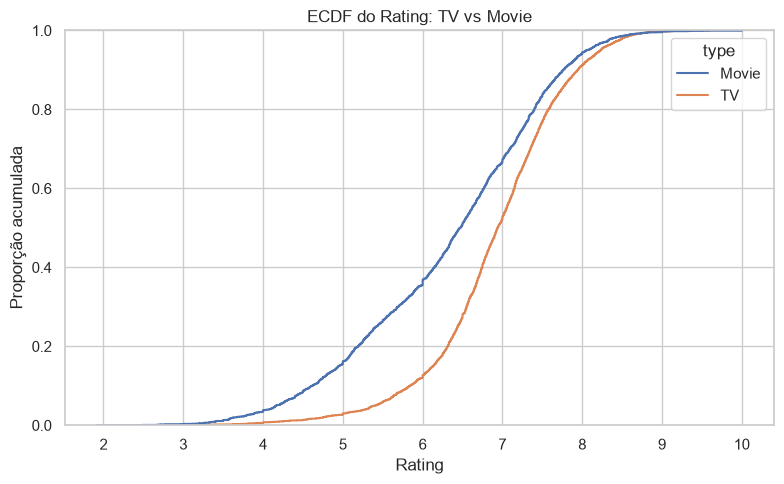

In [138]:
plt.figure(figsize=(8, 5))

sns.ecdfplot(
    data=df[df["type"].isin(["TV", "Movie"])],
    x="rating",
    hue="type"
)

plt.title("ECDF do Rating: TV vs Movie")
plt.xlabel("Rating")
plt.ylabel("Proporção acumulada")

plt.tight_layout()
plt.show()

**Como ler:** em qualquer ponto do eixo X, a altura da curva indica a proporção acumulada de animes com rating menor ou igual àquele valor.

A diferença entre as curvas permite comparar as distribuições de rating de animes TV e Movie. A curva dos animes de TV aparece mais deslocada para a direita, indicando uma tendência de ratings mais altos nesse grupo.

### Métricas de Tendêncial Central

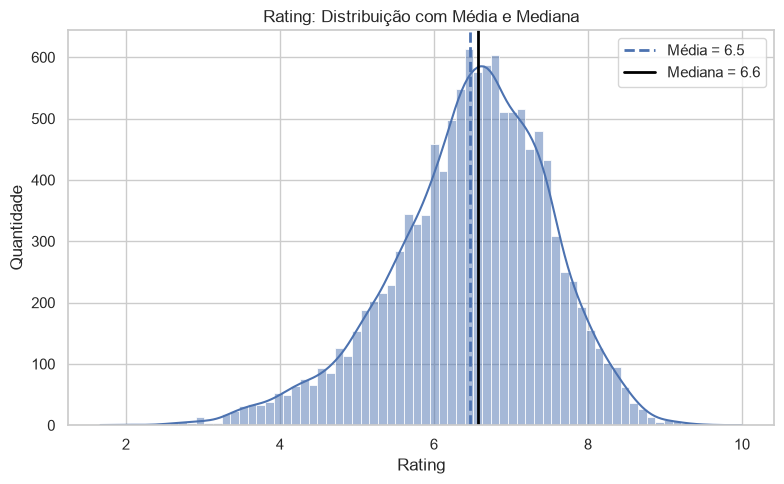

In [139]:
media_rating = df["rating"].mean()
mediana_rating = df["rating"].median()

plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="rating",
    kde=True
)

plt.axvline(
    media_rating,
    linestyle="--",
    linewidth=2,
    label=f"Média = {media_rating:.1f}"
)

plt.axvline(
    mediana_rating,
    color="black",
    linestyle="-",
    linewidth=2,
    label=f"Mediana = {mediana_rating:.1f}"
)

plt.title("Rating: Distribuição com Média e Mediana")
plt.xlabel("Rating")
plt.ylabel("Quantidade")
plt.legend()

plt.tight_layout()
plt.show()

### Dispersão

,var,std,IQR
episodes,2.196360e+03,46.87,11.0
rating,1.050000e+00,1.03,1.3
members,3.005307e+09,54820.68,9212.0


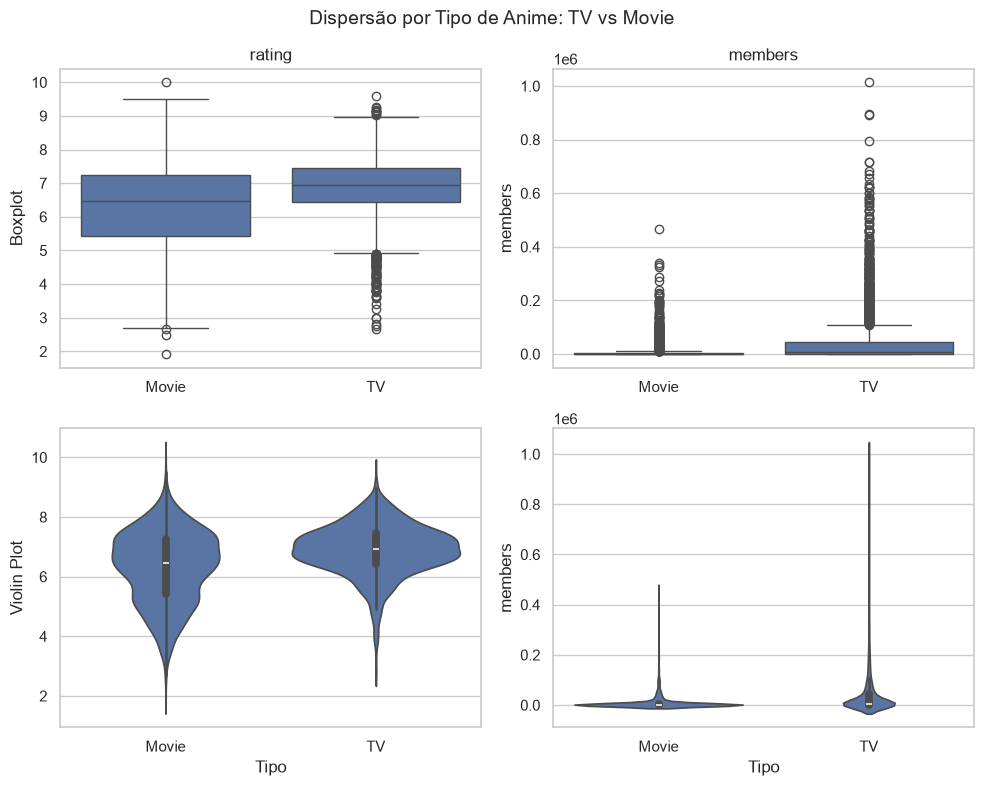

In [140]:
# Medidas de dispersão
dispersao = df[VARS_QUANT].agg(["var", "std"]).T
dispersao["IQR"] = (
    df[VARS_QUANT].quantile(0.75)
    - df[VARS_QUANT].quantile(0.25)
)

display(dispersao.round(2))


### Boxplot e Violin Plot: TV vs Movie

VARS_COMPARACAO = ["rating", "members"]

df_tv_movie = df[df["type"].isin(["TV", "Movie"])]

fig, axes = plt.subplots(
    2,
    len(VARS_COMPARACAO),
    figsize=(10, 8)
)

for i, col in enumerate(VARS_COMPARACAO):

    # Boxplot
    sns.boxplot(
        data=df_tv_movie,
        x="type",
        y=col,
        ax=axes[0, i]
    )

    axes[0, i].set_title(col)
    axes[0, i].set_xlabel("")

    # Violin plot
    sns.violinplot(
        data=df_tv_movie,
        x="type",
        y=col,
        ax=axes[1, i]
    )

    axes[1, i].set_xlabel("Tipo")

axes[0, 0].set_ylabel("Boxplot")
axes[1, 0].set_ylabel("Violin Plot")

fig.suptitle(
    "Dispersão por Tipo de Anime: TV vs Movie",
    fontsize=14
)

plt.tight_layout()
plt.show()

**Interpretação:** Os animes do tipo TV apresentam ratings mais concentrados e mediana ligeiramente superior aos Movies.

Na variável `members`, observa-se forte assimetria e grande quantidade de valores extremos, especialmente entre os animes do tipo TV, mostrando que alguns títulos possuem popularidade muito superior à maioria.

## 4. Tratamento de Dados Ausentes e Outliers

Após analisar o comportamento das variáveis nos dados originais, podemos decidir como tratar os valores ausentes e os possíveis outliers.

Os valores ausentes aparecem principalmente em `genre`, `type`, `episodes` e `rating`. Já os valores extremos mais relevantes aparecem em variáveis como `episodes` e `members`.

Depois do tratamento, as estatísticas serão calculadas novamente para verificar o impacto das decisões tomadas.

### Detecção de Outliers por IQR

A regra clássica marca como outlier qualquer ponto fora de `[Q1 - 1.5*IQR, Q3 + 1.5*IQR]`.

In [141]:
def limites_iqr(serie):
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

resumo_outliers = {}
for col in VARS_QUANT:
    lim_inf, lim_sup = limites_iqr(df[col])
    n_outliers = ((df[col] < lim_inf) | (df[col] > lim_sup)).sum()
    resumo_outliers[col] = {
        "limite_inferior": round(lim_inf, 2),
        "limite_superior": round(lim_sup, 2),
        "n_outliers": n_outliers,
    }

pd.DataFrame(resumo_outliers).T

,limite_inferior,limite_superior,n_outliers
episodes,-15.50,28.50,1123.0
rating,3.93,9.13,229.0
members,-13593.00,23255.00,1900.0


### Visualizando os Outliers

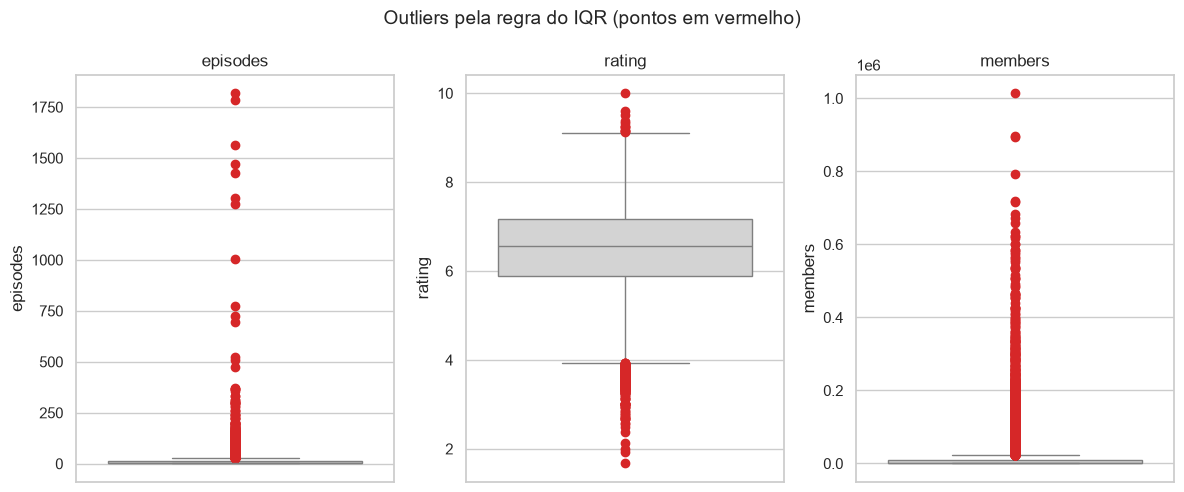

In [142]:
fig, axes = plt.subplots(1, len(VARS_QUANT), figsize=(4 * len(VARS_QUANT), 5))

for i, col in enumerate(VARS_QUANT):
    sns.boxplot(data=df, y=col, color=COR_NEUTRA,
                flierprops=dict(markerfacecolor=COR_ALERTA, markeredgecolor=COR_ALERTA, marker="o"),
                ax=axes[i])
    axes[i].set_title(col)

fig.suptitle("Outliers pela regra do IQR (pontos em vermelho)", fontsize=14)
plt.tight_layout()
plt.show()

**Interpretação dos outliers**

Os valores extremos encontrados em `episodes` e `members` não representam necessariamente erros.

Um anime pode realmente possuir centenas ou até mais de mil episódios, assim como alguns títulos podem possuir uma quantidade de membros muito superior à maioria.

Portanto, esses valores são classificados principalmente como **outliers estatísticos legítimos**. Em vez de removê-los automaticamente, podemos mantê-los ou utilizar transformações que reduzam sua influência em determinadas análises.

### Decidindo o Tratamento dos Dados Ausentes

A quantidade de registros afetados por valores ausentes é pequena em relação ao tamanho total do dataset.

Optamos por remover as linhas que possuem valores ausentes em `genre`, `type`, `episodes` ou `rating`, evitando a introdução de valores artificiais por imputação.

Após o tratamento, o dataset passou de 12.294 para 11.830 registros, com remoção de 464 linhas. Essa redução representa uma parcela relativamente pequena da base e será avaliada novamente nas distribuições após o tratamento.

In [143]:
linhas_antes = df.shape[0]

df_antes = df.copy()

df = df.dropna(
    subset=["genre", "type", "episodes", "rating"]
).reset_index(drop=True)

linhas_depois = df.shape[0]

print(
    f"Linhas antes: {linhas_antes} | "
    f"Linhas depois: {linhas_depois} | "
    f"Removidas: {linhas_antes - linhas_depois}"
)

Linhas antes: 12294 | Linhas depois: 11830 | Removidas: 464


**Decidindo o Tratamento dos Outliers**

Os valores extremos encontrados em members podem representar animes realmente muito populares, portanto não devem ser removidos automaticamente. Neste caso, vamos manter os valores originais.

Para visualizar uma possível forma de reduzir a assimetria da distribuição, aplicaremos uma transformação logarítmica em members. Essa transformação pode ser útil em análises futuras caso a grande diferença de popularidade entre os animes prejudique algum método estatístico.

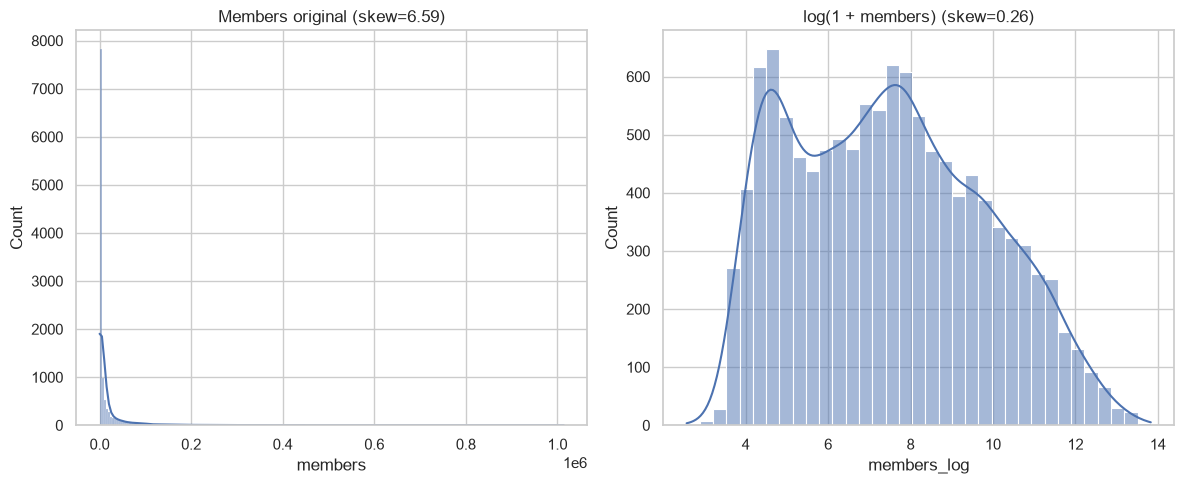

In [144]:
df["members_log"] = np.log1p(df["members"])

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.histplot(
    data=df,
    x="members",
    kde=True,
    ax=axes[0]
)

axes[0].set_title(
    f"Members original (skew={df['members'].skew():.2f})"
)

sns.histplot(
    data=df,
    x="members_log",
    kde=True,
    ax=axes[1]
)

axes[1].set_title(
    f"log(1 + members) (skew={df['members_log'].skew():.2f})"
)

plt.tight_layout()
plt.show()

**Interpretação:** A transformação logarítmica reduziu fortemente a assimetria de `members`.

Na distribuição original, a variável apresentava skewness muito elevada. Após aplicar `log(1 + members)`, a distribuição tornou-se muito mais equilibrada.

A variável `members_log` será utilizada em visualizações nas quais a grande assimetria de `members` dificultaria a interpretação, sem apagar os valores extremos legítimos.

## 5. Estatística Descritiva pt 2

Fechando o ciclo iterativo: tratamos os ausentes e decidimos manter os outliers. Agora rodamos a mesma bateria de estatísticas da Seção 3 para comparar diretamente com o "antes".

In [145]:
desc_depois = df[VARS_QUANT].describe().T
desc_depois["skewness"] = df[VARS_QUANT].skew()
desc_depois["kurtosis"] = df[VARS_QUANT].kurtosis()

(
    desc_depois[["mean", "50%", "std", "min", "max", "skewness", "kurtosis"]]
    .rename(columns={"50%": "median"})
    .round(2)
    .style.format(precision=2)
    .background_gradient(cmap="Blues", subset=["skewness", "kurtosis"])
)

,mean,median,std,min,max,skewness,kurtosis
episodes,12.49,2.00,47.10,1.00,1818.00,23.28,726.25
rating,6.48,6.57,1.02,1.67,10.00,-0.54,0.51
members,18511.00,1589.50,55371.44,12.00,1013917.00,6.59,61.40


### Comparando "antes"x "depois""



In [146]:
comparacao = pd.DataFrame({
    "skewness_antes": desc["skewness"],
    "skewness_depois": desc_depois["skewness"],
    "kurtosis_antes": desc["kurtosis"],
    "kurtosis_depois": desc_depois["kurtosis"],
})
comparacao["delta_skewness"] = (comparacao["skewness_depois"] - comparacao["skewness_antes"]).round(3)
comparacao["delta_kurtosis"] = (comparacao["kurtosis_depois"] - comparacao["kurtosis_antes"]).round(3)
comparacao.round(3)

,skewness_antes,skewness_depois,kurtosis_antes,kurtosis_depois,delta_skewness,delta_kurtosis
episodes,23.386,23.277,733.277,726.254,-0.108,-7.022
rating,-0.544,-0.538,0.508,0.506,0.005,-0.002
members,6.683,6.588,62.856,61.401,-0.095,-1.455


**Interpretação:** As medidas estatísticas mudaram pouco após o tratamento dos valores ausentes.

As variáveis `episodes` e `members` continuam apresentando forte assimetria, enquanto `rating` mantém comportamento semelhante ao observado anteriormente.

Isso indica que a remoção dos registros ausentes não alterou de forma significativa a estrutura das distribuições.

**O rating ainda rejeita normalidade?**

Vamos rodar novamente o teste de Shapiro-Wilk, agora comparando os dados antes e depois do tratamento dos valores ausentes.

In [147]:
rating_antes = df_antes["rating"].dropna()
rating_depois = df["rating"].dropna()

amostra_antes = rating_antes.sample(
    n=min(5000, len(rating_antes)),
    random_state=42
)

amostra_depois = rating_depois.sample(
    n=min(5000, len(rating_depois)),
    random_state=42
)

stat_sw_antes, p_valor_sw_antes = stats.shapiro(amostra_antes)
stat_sw_depois, p_valor_sw_depois = stats.shapiro(amostra_depois)

print(
    f"Shapiro-Wilk (antes) — rating: "
    f"estatística={stat_sw_antes:.4f}, "
    f"p-valor={p_valor_sw_antes:.4g}"
)

print(
    f"Shapiro-Wilk (depois) — rating: "
    f"estatística={stat_sw_depois:.4f}, "
    f"p-valor={p_valor_sw_depois:.4g}"
)

print(
    "Rejeita normalidade depois?",
    "Sim" if p_valor_sw_depois < 0.05 else "Não"
)

Shapiro-Wilk (antes) — rating: estatística=0.9832, p-valor=6.236e-24
Shapiro-Wilk (depois) — rating: estatística=0.9846, p-valor=6.483e-23
Rejeita normalidade depois? Sim


**Visualizando antes x depois, lado a lado**

Vamos sobrepor as distribuições de `rating` e `members`, comparando a versão original (`df_antes`) com a versão após o tratamento (`df`).

O objetivo é verificar visualmente se a remoção das linhas com valores ausentes provocou alterações importantes nas distribuições.

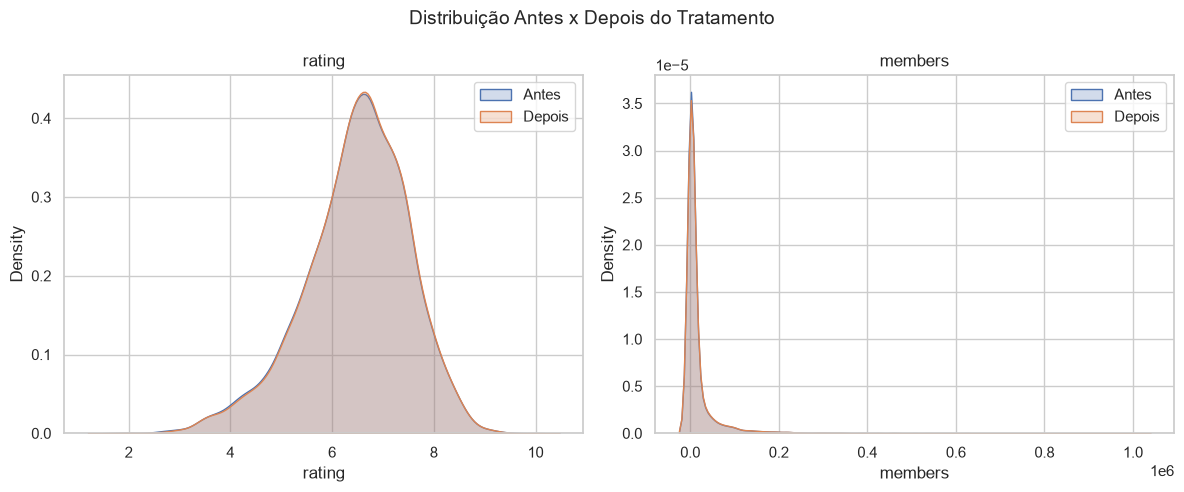

In [148]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, col in zip(axes, ["rating", "members"]):
    sns.kdeplot(
        x=df_antes[col].dropna(),
        fill=True,
        label="Antes",
        ax=ax
    )

    sns.kdeplot(
        x=df[col].dropna(),
        fill=True,
        label="Depois",
        ax=ax
    )

    ax.set_title(col)
    ax.legend()

fig.suptitle(
    "Distribuição Antes x Depois do Tratamento",
    fontsize=14
)

plt.tight_layout()
plt.show()

**Interpretação:** As distribuições antes e depois do tratamento apresentam grande sobreposição, indicando que a remoção dos registros com valores ausentes provocou pouca alteração no formato das distribuições.

Esse resultado sugere que o tratamento realizado teve baixo impacto sobre a estrutura geral dos dados.

## 6. Princípio Relacional

### Análise de Variáveis Qualitativas

Agora focaremos na avaliação de frequência e desbalanceamento das variáveis qualitativas.




#### Frequências absolutas e relativas

In [149]:
# Gêneros considerados individualmente
generos_individuais = (
    df["genre"]
    .dropna()
    .str.split(", ")
    .explode()
)

freq_genre_abs = generos_individuais.value_counts()
freq_genre_rel = generos_individuais.value_counts(
    normalize=True
).round(3)

print("\n--- genre ---")

print(
    pd.concat(
        [
            freq_genre_abs.rename("absoluta"),
            freq_genre_rel.rename("relativa")
        ],
        axis=1
    )
)

# Frequência de tipo
freq_type_abs = df["type"].value_counts()
freq_type_rel = df["type"].value_counts(
    normalize=True
).round(3)

print("\n--- type ---")

print(
    pd.concat(
        [
            freq_type_abs.rename("absoluta"),
            freq_type_rel.rename("relativa")
        ],
        axis=1
    )
)


--- genre ---
               absoluta  relativa
genre                            
Comedy             4483     0.127
Action             2748     0.078
Adventure          2293     0.065
Fantasy            2219     0.063
Sci-Fi             2028     0.058
Drama              1972     0.056
Shounen            1669     0.047
Kids               1550     0.044
Romance            1436     0.041
Slice of Life      1180     0.034
School             1164     0.033
Hentai             1099     0.031
Supernatural        993     0.028
Mecha               927     0.026
Music               832     0.024
Historical          787     0.022
Magic               742     0.021
Ecchi               627     0.018
Shoujo              587     0.017
Seinen              530     0.015
Sports              527     0.015
Mystery             482     0.014
Super Power         445     0.013
Military            415     0.012
Parody              397     0.011
Space               376     0.011
Horror              360     0.010

#### Visualizando as frequências

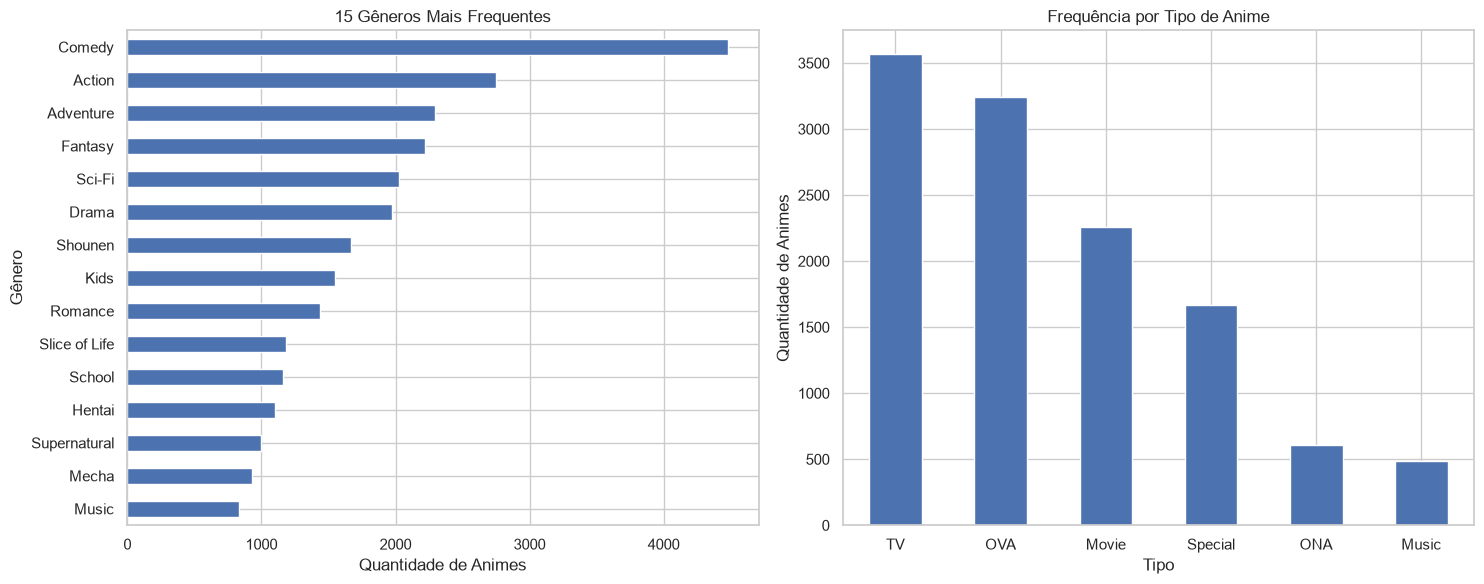

In [150]:
# Separar os gêneros individuais
generos = (
    df["genre"]
    .dropna()
    .str.split(", ")
    .explode()
    .value_counts()
    .head(15)
)

# Frequência dos tipos de anime
tipos = df["type"].value_counts()

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Top 15 gêneros
generos.sort_values().plot(
    kind="barh",
    ax=axes[0]
)

axes[0].set_title("15 Gêneros Mais Frequentes")
axes[0].set_xlabel("Quantidade de Animes")
axes[0].set_ylabel("Gênero")

# Tipos de anime
tipos.plot(
    kind="bar",
    ax=axes[1]
)

axes[1].set_title("Frequência por Tipo de Anime")
axes[1].set_xlabel("Tipo")
axes[1].set_ylabel("Quantidade de Animes")
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

**Interpretação:** As categorias não apresentam a mesma frequência. Alguns tipos e gêneros aparecem com muito mais frequência que outros, o que será analisado de forma mais objetiva por meio da razão de desbalanceamento e da entropia normalizada.

#### Desbalanceamento das Variáveis Qualitativas

- **Razão de desbalanceamento** — frequência da categoria majoritária dividida pela frequência da categoria minoritária. Quanto maior o valor, maior a diferença entre as categorias.
- **Entropia de Shannon normalizada** — valores próximos de 1 indicam distribuição mais equilibrada, enquanto valores próximos de 0 indicam forte concentração em poucas categorias.

Aplicaremos essas métricas às variáveis `type` e aos gêneros individuais.

In [151]:
from scipy.stats import entropy

def metrica_desbalanceamento(serie):
    contagens = serie.value_counts()
    razao = contagens.max() / contagens.min()
    props = contagens / contagens.sum()
    n_classes = len(contagens)

    ent_normalizada = (
        entropy(props, base=2) / np.log2(n_classes)
        if n_classes > 1
        else np.nan
    )

    return pd.Series({
        "n_classes": n_classes,
        "razao_desbalanceamento": round(razao, 2),
        "entropia_normalizada": round(ent_normalizada, 3),
    })


# Tipo de anime
resultado_type = metrica_desbalanceamento(df["type"])

# Gêneros individuais
generos = (
    df["genre"]
    .dropna()
    .str.split(", ")
    .explode()
)

resultado_genre = metrica_desbalanceamento(generos)

resultado = pd.DataFrame({
    "type": resultado_type,
    "genre": resultado_genre
}).T

resultado

,n_classes,razao_desbalanceamento,entropia_normalizada
type,6.0,7.33,0.889
genre,43.0,121.16,0.869


**Interpretação:** A variável `type` apresenta desbalanceamento moderado, mas sua entropia normalizada permanece relativamente alta.

A variável `genre` apresenta uma razão de desbalanceamento muito maior, indicando que alguns gêneros são muito frequentes enquanto outros aparecem poucas vezes. Apesar disso, a entropia ainda é relativamente elevada, mostrando que os dados estão distribuídos entre vários gêneros.

### Análise Bivariada

Nesta etapa analisamos como diferentes características dos animes se relacionam entre si.

Serão estudadas relações entre variáveis quantitativas, como `rating`, `episodes` e `members`, e variáveis qualitativas, como `type` e `genre`.

#### Quantitativa x Quantitativa - Correlação

Conhecemos três técnicas principais de correlação:

- **Pearson:** mede relações lineares e é mais sensível a outliers;
- **Spearman:** mede relações monotônicas e não exige normalidade;
- **Kendall:** também avalia associação por ordenação.

Como `rating` rejeitou normalidade e `episodes` e `members` apresentam forte assimetria e valores extremos, a correlação de Spearman será considerada a principal referência. As três serão calculadas para comparação.

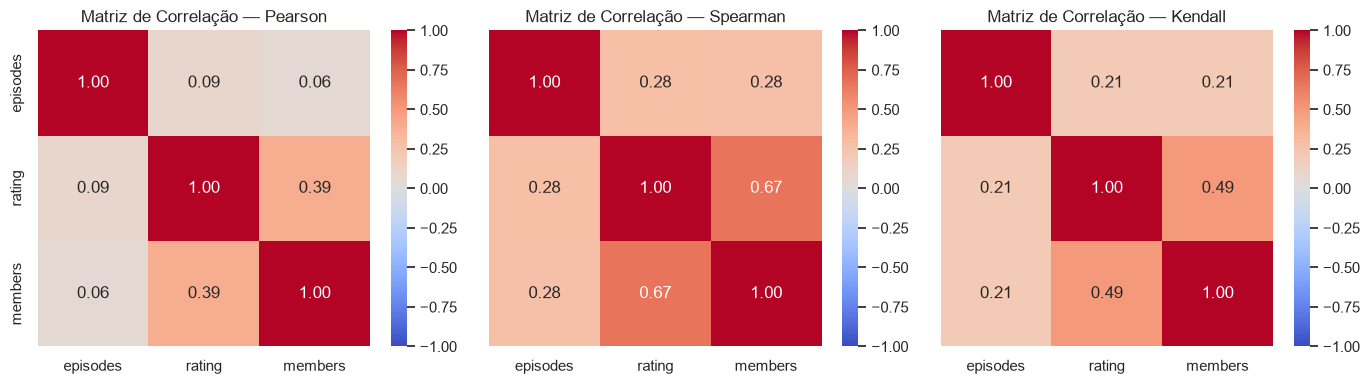

In [152]:
corr_pearson = df[VARS_QUANT].corr(method="pearson")
corr_spearman = df[VARS_QUANT].corr(method="spearman")
corr_kendall = df[VARS_QUANT].corr(method="kendall")

fig, ax = plt.subplots(1,3,figsize=(14, 4),sharey=True)
sns.heatmap(corr_pearson, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax[0])
ax[0].set_title("Matriz de Correlação — Pearson")
sns.heatmap(corr_spearman, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax[1])
ax[1].set_title("Matriz de Correlação — Spearman")
sns.heatmap(corr_kendall, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax[2])
ax[2].set_title("Matriz de Correlação — Kendall")
plt.tight_layout()
plt.show()


Como os dados do triângulo superior e inferior são simétricos, poderíamos plotar a matriz de correlação da seguinte forma.

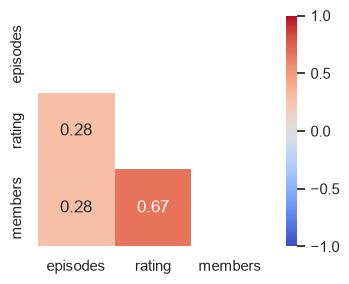

In [153]:
mask = np.triu(np.ones_like(corr_spearman, dtype=bool))

plt.figure(figsize=(4, 3))
sns.heatmap(corr_spearman, mask=mask, annot=True, cmap="coolwarm", fmt=".2f", square=True, vmin=-1, vmax=1,)
plt.grid(False)

plt.tight_layout()
plt.show()

**Interpretação:** Pearson, Spearman e Kendall medem tipos de associação diferentes. Como as variáveis apresentam assimetria e valores extremos, a correlação de Spearman é utilizada como principal referência, por ser menos sensível a essas características do que Pearson.

#### Dispersão (scatter) entre duas variáveis quantitativas

Escolhemos analisar `rating` × `members_log` para verificar se existe uma relação entre avaliação e popularidade.

A transformação logarítmica de `members` é utilizada porque a variável original apresenta forte assimetria e valores extremos, dificultando a visualização.

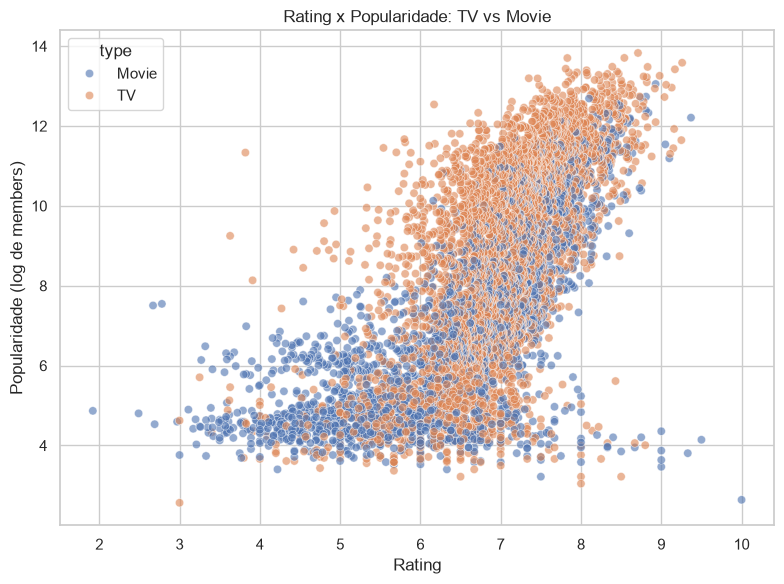

In [154]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=df[df["type"].isin(["TV", "Movie"])],
    x="rating",
    y="members_log",
    hue="type",
    alpha=0.6
)

plt.title("Rating x Popularidade: TV vs Movie")
plt.xlabel("Rating")
plt.ylabel("Popularidade (log de members)")

plt.tight_layout()
plt.show()

**Interpretação:** O gráfico sugere uma relação positiva entre rating e popularidade: títulos com maior número de membros tendem a apresentar ratings mais altos.

Também existem pontos afastados da concentração principal, mostrando que popularidade elevada não implica necessariamente uma avaliação elevada e vice-versa.

#### Quantitativa x Qualitativa: Comparando Grupos

Para comparar uma variável quantitativa entre diferentes categorias, podemos utilizar testes paramétricos e não paramétricos.

Para dois grupos, serão comparados o **T-Test de Welch** e o **Mann-Whitney U**.

Para três ou mais grupos, serão comparados a **ANOVA** e o **Kruskal-Wallis**.

Como as variáveis analisadas apresentam desvios de normalidade e forte assimetria em alguns casos, os testes não paramétricos serão considerados como principal referência para interpretação.

In [155]:
resultados_comparacao = []

VARS_TESTE = ["rating", "members"]

for col in VARS_TESTE:
    grupo_tv = df.loc[df["type"] == "TV", col].dropna()
    grupo_movie = df.loc[df["type"] == "Movie", col].dropna()

    stat_t, p_t = stats.ttest_ind(
        grupo_tv,
        grupo_movie,
        equal_var=False
    )

    stat_u, p_u = stats.mannwhitneyu(
        grupo_tv,
        grupo_movie,
        alternative="two-sided"
    )

    resultados_comparacao.append({
        "variavel": col,
        "p_valor_ttest": f"{p_t:.4g}",
        "p_valor_mannwhitney": f"{p_u:.4g}",
        "significativo_ambos": (p_t < 0.05) and (p_u < 0.05)
    })

pd.DataFrame(
    resultados_comparacao
).set_index("variavel")

,p_valor_ttest,p_valor_mannwhitney,significativo_ambos
variavel,,,
rating,8.4e-89,1.804e-75,True
members,2.009e-90,3.565e-144,True


**Interpretação:** Tanto o T-Test de Welch quanto o Mann-Whitney indicam diferenças estatisticamente significativas entre TV e Movie para `rating` e `members`.

Como as distribuições não atendem bem à hipótese de normalidade, o resultado do Mann-Whitney deve ser priorizado.

### Comparação entre três ou mais grupos — ANOVA x Kruskal-Wallis

Agora vamos comparar o `rating` entre todos os diferentes tipos de anime, como TV, Movie, OVA, ONA e Special.

A ANOVA será apresentada como comparação paramétrica, enquanto o Kruskal-Wallis será utilizado como principal referência não paramétrica.

ANOVA — rating entre tipos de anime: estatística=360.288, p-valor=0
Kruskal-Wallis — rating entre tipos de anime: estatística=1545.764, p-valor=0


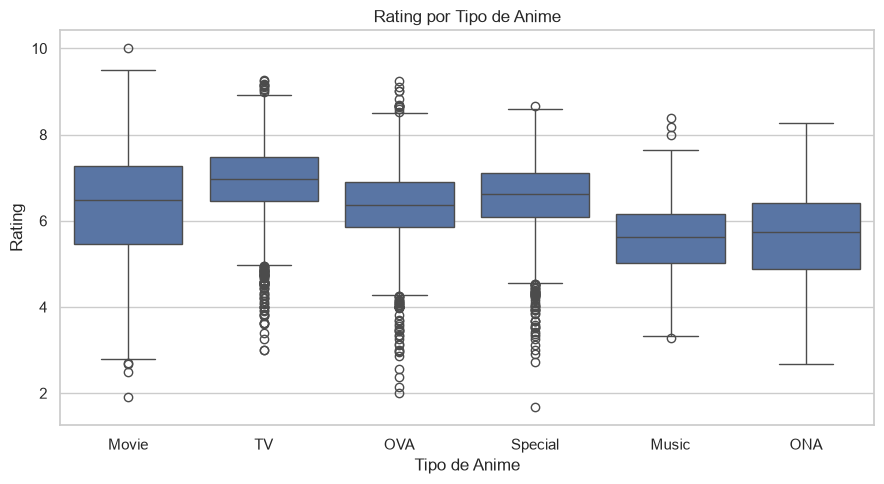

In [156]:
grupos_type = [
    grupo["rating"].dropna().values
    for _, grupo in df.groupby("type")
]

# ANOVA - paramétrico
stat_anova, p_anova = stats.f_oneway(*grupos_type)

# Kruskal-Wallis - não paramétrico
stat_kw, p_kw = stats.kruskal(*grupos_type)

print(
    f"ANOVA — rating entre tipos de anime: "
    f"estatística={stat_anova:.3f}, p-valor={p_anova:.5g}"
)

print(
    f"Kruskal-Wallis — rating entre tipos de anime: "
    f"estatística={stat_kw:.3f}, p-valor={p_kw:.5g}"
)

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="type",
    y="rating"
)

plt.title("Rating por Tipo de Anime")
plt.xlabel("Tipo de Anime")
plt.ylabel("Rating")

plt.tight_layout()
plt.show()

**Interpretação:** O teste de Kruskal-Wallis permite verificar se pelo menos um dos tipos de anime apresenta uma distribuição de rating diferente dos demais.

Caso o p-valor seja inferior a 0,05, rejeitamos a hipótese de que todos os grupos possuem a mesma distribuição. O teste não identifica sozinho quais pares específicos são diferentes.

#### Qualitativa x Qualitativa — Gênero x Tipo de Anime

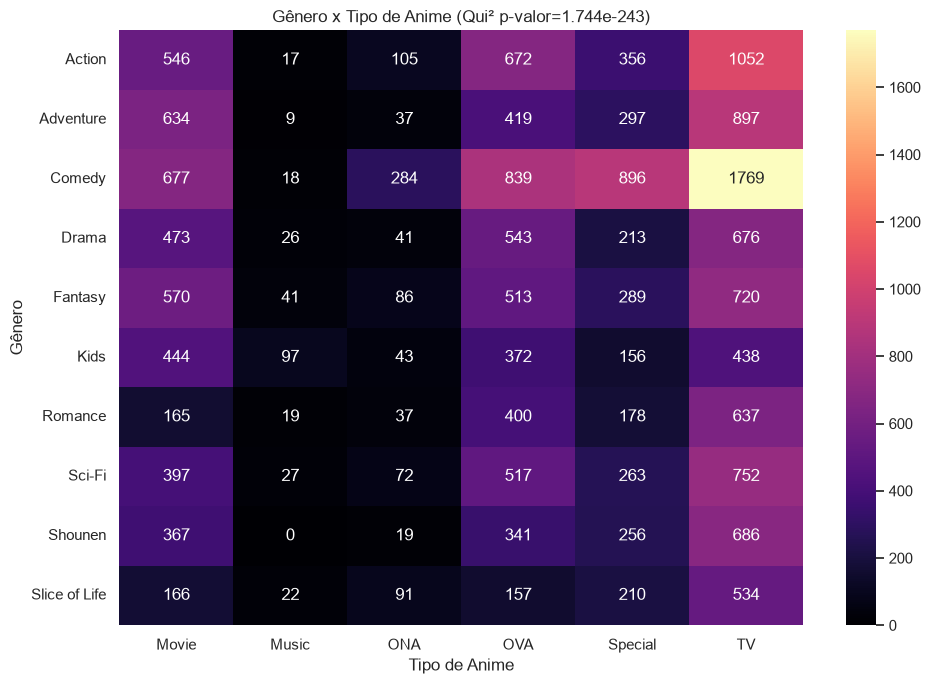

In [157]:
# Separar os gêneros individuais
df_genres = (
    df.assign(genre_individual=df["genre"].str.split(", "))
      .explode("genre_individual")
)

# Selecionar os 10 gêneros mais frequentes
top_generos = (
    df_genres["genre_individual"]
    .value_counts()
    .head(10)
    .index
)

df_top = df_genres[
    df_genres["genre_individual"].isin(top_generos)
]

# Tabela de contingência
contingencia = pd.crosstab(
    df_top["genre_individual"],
    df_top["type"]
)

# Teste Qui-quadrado
chi2, p_chi2, gl, esperado = stats.chi2_contingency(contingencia)

# Gráfico
plt.figure(figsize=(10, 7))

sns.heatmap(
    contingencia,
    annot=True,
    fmt="d",
    cmap="magma"
)

plt.title(
    f"Gênero x Tipo de Anime (Qui² p-valor={p_chi2:.4g})"
)

plt.xlabel("Tipo de Anime")
plt.ylabel("Gênero")

plt.tight_layout()
plt.show()

**Interpretação:** O teste Qui-Quadrado permite verificar se existe associação entre o gênero e o tipo do anime.

Se o p-valor for inferior a 0,05, rejeitamos a hipótese de independência, indicando evidências de associação entre as duas variáveis.

O heatmap permite observar quais combinações entre gêneros e tipos aparecem com maior frequência.

#### Análise das Faixas de Rating e Popularidade

Para complementar a análise, criamos categorias a partir das variáveis quantitativas `rating` e `members`.

O rating foi dividido em faixas de avaliação e a quantidade de membros em faixas de popularidade.

Essas novas categorias permitem observar como a participação dos diferentes tipos de anime varia conforme avaliação e popularidade.

In [158]:
# Criando faixas de avaliação
df["faixa_rating"] = pd.cut(
    df["rating"],
    bins=[0, 5, 6, 7, 8, 10],
    labels=["Até 5", "5-6", "6-7", "7-8", "8-10"],
    include_lowest=True
)

# Criando faixas de popularidade
df["faixa_popularidade"] = pd.cut(
    df["members"],
    bins=[0, 10000, 100000, 500000, float("inf")],
    labels=["Até 10 mil", "10 mil-100 mil", "100 mil-500 mil", "Mais de 500 mil"],
    include_lowest=True
)

print("Desbalanceamento - faixa de rating:")
print(metrica_desbalanceamento(df["faixa_rating"]))

print("\nDesbalanceamento - faixa de popularidade:")
print(metrica_desbalanceamento(df["faixa_popularidade"]))

Desbalanceamento - faixa de rating:
n_classes                 5.00
razao_desbalanceamento    8.11
entropia_normalizada      0.87
dtype: float64

Desbalanceamento - faixa de popularidade:
n_classes                   4.000
razao_desbalanceamento    306.590
entropia_normalizada        0.498
dtype: float64


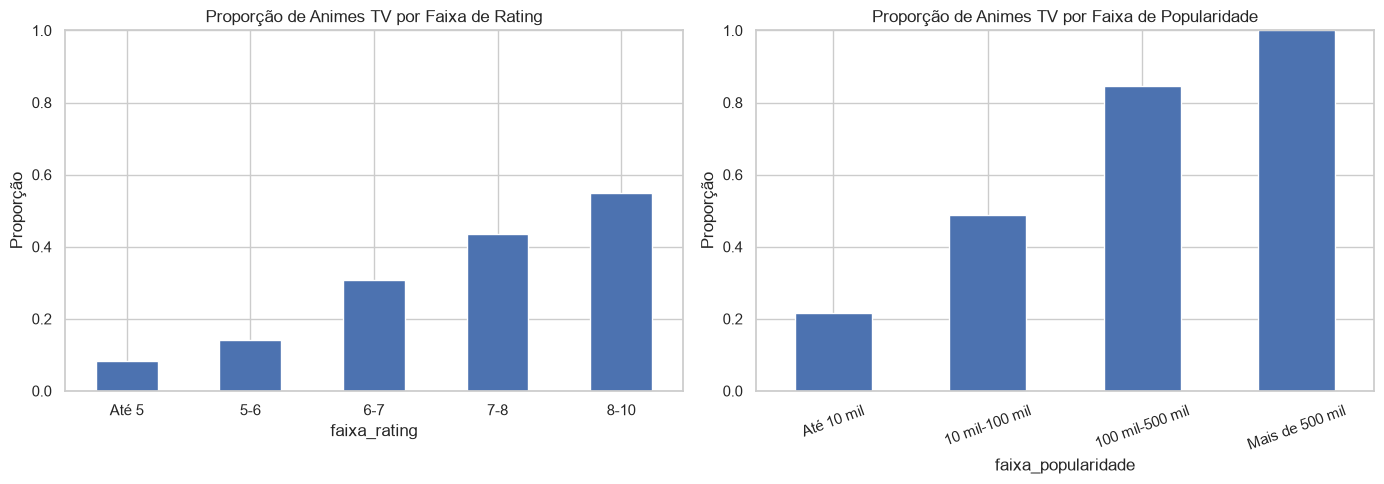

In [159]:
prop_por_rating = pd.crosstab(
    df["faixa_rating"],
    df["type"],
    normalize="index"
).round(3)

prop_por_pop = pd.crosstab(
    df["faixa_popularidade"],
    df["type"],
    normalize="index"
).round(3)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Proporção de TV por faixa de rating
prop_por_rating["TV"].plot(
    kind="bar",
    ax=axes[0]
)

axes[0].set_title("Proporção de Animes TV por Faixa de Rating")
axes[0].set_ylabel("Proporção")
axes[0].set_ylim(0, 1)
axes[0].tick_params(axis="x", rotation=0)

# Proporção de TV por faixa de popularidade
prop_por_pop["TV"].plot(
    kind="bar",
    ax=axes[1]
)

axes[1].set_title("Proporção de Animes TV por Faixa de Popularidade")
axes[1].set_ylabel("Proporção")
axes[1].set_ylim(0, 1)
axes[1].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

**Interpretação:** A proporção de animes do tipo TV aumenta conforme crescem as faixas de rating e de popularidade.

Entre os títulos com ratings mais elevados, a participação de animes TV é maior. O mesmo comportamento é ainda mais evidente nas faixas de maior popularidade.

Esses resultados descrevem o comportamento observado neste dataset e não implicam relação de causalidade.

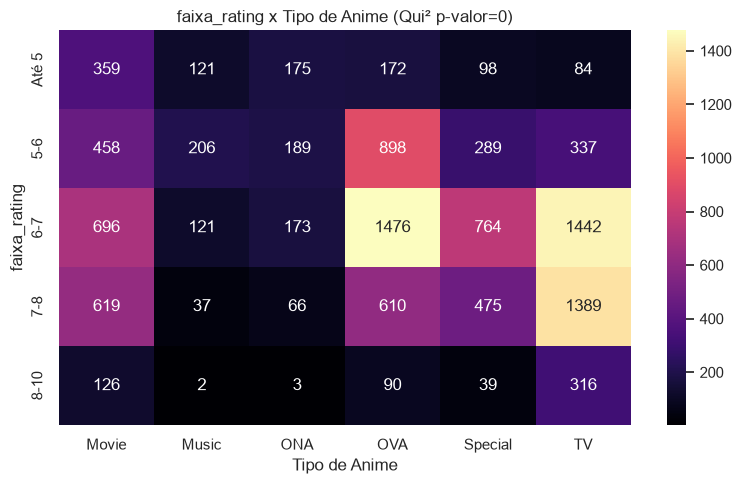

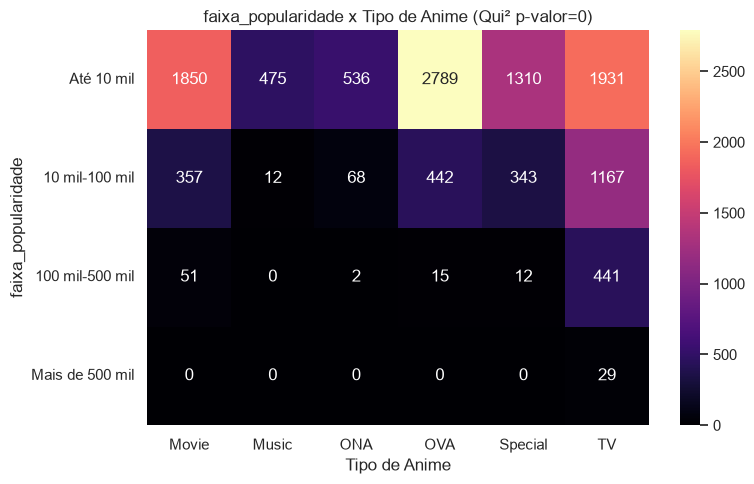

In [160]:
for atributo in ["faixa_rating", "faixa_popularidade"]:

    contingencia = pd.crosstab(
        df[atributo],
        df["type"]
    )

    chi2, p_valor, gl, esperado = stats.chi2_contingency(contingencia)

    fig, ax = plt.subplots(figsize=(8, 5))

    sns.heatmap(
        contingencia,
        annot=True,
        fmt="d",
        cmap="magma",
        ax=ax
    )

    ax.set_title(
        f"{atributo} x Tipo de Anime "
        f"(Qui² p-valor={p_valor:.4g})"
    )

    ax.set_xlabel("Tipo de Anime")
    ax.set_ylabel(atributo)

    plt.tight_layout()
    plt.show()

**Interpretação:** O teste Qui-Quadrado permite avaliar se existe associação entre o tipo do anime e as faixas de rating ou popularidade.

Um p-valor inferior a 0,05 indica evidências de associação entre as variáveis. Entretanto, o teste identifica associação estatística e não uma relação de causa e efeito.

#### Outliers bivariados

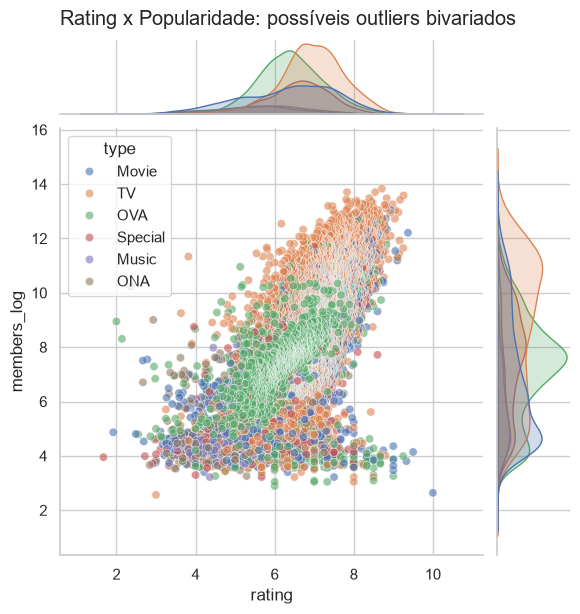

In [161]:
sns.jointplot(
    data=df,
    x="rating",
    y="members_log",
    hue="type",
    alpha=0.6,
    height=6
)

plt.suptitle(
    "Rating x Popularidade: possíveis outliers bivariados",
    y=1.02
)

plt.show()

**Interpretação:** A maior parte dos animes forma uma região relativamente concentrada na relação entre `rating` e `members_log`.

Alguns registros aparecem afastados dessa concentração principal e podem representar possíveis outliers bivariados, como títulos com rating muito alto e baixa popularidade ou títulos muito populares com avaliações relativamente baixas.

#### Análise Multivariada

##### Matriz de Correlação

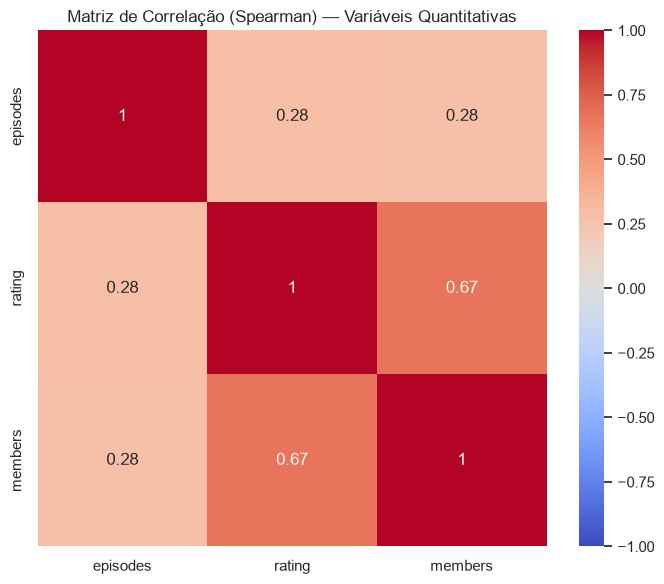

In [162]:
plt.figure(figsize=(7, 6))
sns.heatmap(df[VARS_QUANT].corr(method="spearman"), annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Matriz de Correlação (Spearman) — Variáveis Quantitativas")
plt.tight_layout()
plt.show()


**Como interpretar:**


*   |r| < 0.3 ~ fraca,
*   0.3 < |r| < 0.7 ~ moderada,
*  |r| > 0.7 ~ forte.

Alguma correlação chama atenção por ser forte o suficiente pra sugerir redundância entre variáveis?

##### Correlograma

Text(0.5, 1.02, 'Correlograma: Dispersão × Correlação de Spearman')

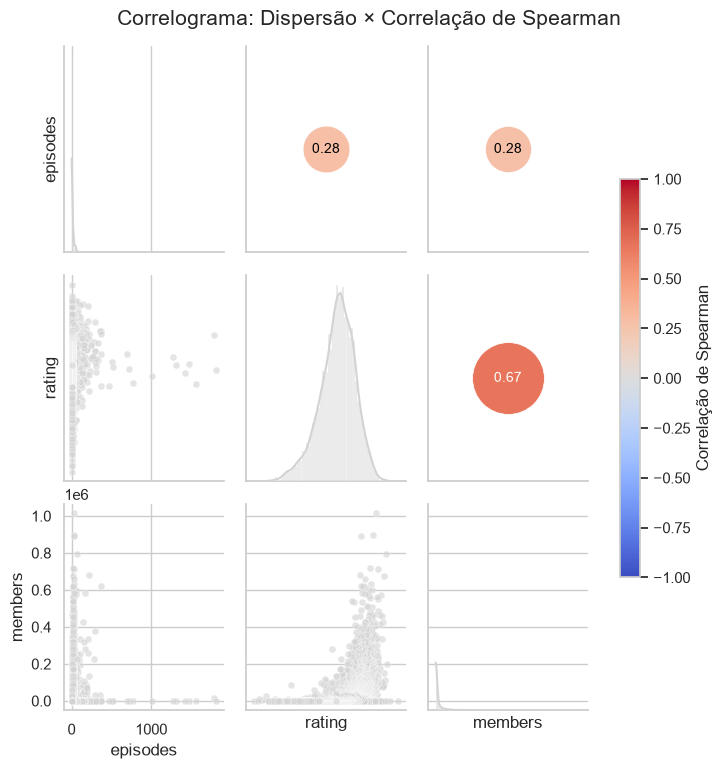

In [163]:
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize

def circulo_correlacao(x, y, **kwargs):
    r = stats.spearmanr(x, y, nan_policy="omit").statistic
    ax = plt.gca()
    ax.scatter(
        [0.5], [0.5],
        s=abs(r) * 4000,          # tamanho proporcional à força da correlação
        c=[r], cmap='coolwarm', vmin=-1, vmax=1,
        transform=ax.transAxes, edgecolor="white", linewidth=0.5,
    )
    ax.annotate(f"{r:.2f}", xy=(0.5, 0.5), xycoords=ax.transAxes,
                ha="center", va="center", fontsize=10,
                color="white" if abs(r) > 0.5 else "black")
    ax.set_xticks([]); ax.set_yticks([])
    ax.grid(False)

g = sns.PairGrid(df[VARS_QUANT], diag_sharey=False)
g.map_lower(sns.scatterplot, color=COR_NEUTRA, alpha=0.6, s=25)
g.map_diag(sns.histplot, color=COR_NEUTRA, kde=True)
g.map_upper(circulo_correlacao)

# barra de cor única, compartilhada (cada subplot superior tem seu próprio scatter)
sm = ScalarMappable(norm=Normalize(-1, 1), cmap='coolwarm')
sm.set_array([])
g.fig.colorbar(sm, ax=g.axes, shrink=0.6, label="Correlação de Spearman")

g.fig.suptitle(
    "Correlograma: Dispersão × Correlação de Spearman",
    y=1.02,
    fontsize=15
)


## Síntese Final

A análise exploratória do dataset de animes permitiu identificar alguns padrões importantes:

1. As variáveis `episodes` e `members` apresentam forte assimetria positiva, causada por poucos títulos com quantidade muito elevada de episódios ou membros.

2. A variável `rating` possui uma distribuição mais concentrada, embora os testes estatísticos indiquem que ela não segue uma distribuição normal.

3. A transformação logarítmica de `members` reduziu significativamente sua assimetria, tornando a distribuição mais adequada para determinadas visualizações e análises.

4. O tratamento dos valores ausentes produziu poucas alterações nas distribuições das variáveis, indicando que a remoção desses registros teve baixo impacto sobre a estrutura geral dos dados.

5. Foram observadas diferenças estatisticamente significativas entre animes TV e Movie em variáveis como `rating` e `members`. Também foram identificadas associações entre o tipo do anime e suas faixas de rating e popularidade.

### Declaração de Uso de IA

Foi utilizado o ChatGPT como ferramenta de apoio durante o desenvolvimento deste trabalho.

A ferramenta foi utilizada para auxiliar na adaptação do notebook-base ao dataset de animes, revisão de código e ajuda na interpretação dos resultados estatísticos, para saber se estavam produzindo resultados adequados.


In [164]:
from pathlib import Path

raiz = Path.cwd()
if raiz.name == "notebooks":
    raiz = raiz.parent

if not (raiz / "app.py").exists():
    raise FileNotFoundError(
        "O notebook precisa estar na pasta do projeto ou em notebooks."
    )

destino = raiz / "data" / "clean" / "dataset.csv"
destino.parent.mkdir(parents=True, exist_ok=True)

df.to_csv(destino, index=False)

print(f"Dados tratados salvos em: {destino}")
print(f"Quantidade de animes: {len(df)}")

Dados tratados salvos em: c:\Users\josev\Desktop\codigos\AVD-20262-pratica-streamlit-main\data\clean\dataset.csv
Quantidade de animes: 11830
